In [288]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay
import warnings
warnings.simplefilter(action='ignore',category=FutureWarning)

In [289]:
# Load the dataset
data = pd.read_csv('zoo[1].csv')

In [290]:
# 1. Data Analysis using Visualizations
print(data.head())
print(data.info())
print(data.describe())

  animal name  hair  feathers  eggs  milk  airborne  aquatic  predator  \
0    aardvark     1         0     0     1         0        0         1   
1    antelope     1         0     0     1         0        0         0   
2        bass     0         0     1     0         0        1         1   
3        bear     1         0     0     1         0        0         1   
4        boar     1         0     0     1         0        0         1   

   toothed  backbone  breathes  venomous  fins  legs  tail  domestic  catsize  \
0        1         1         1         0     0     4     0         0        1   
1        1         1         1         0     0     4     1         0        1   
2        1         1         0         0     1     0     1         0        0   
3        1         1         1         0     0     4     0         0        1   
4        1         1         1         0     0     4     1         0        1   

   type  
0     1  
1     1  
2     4  
3     1  
4     1  
<class '

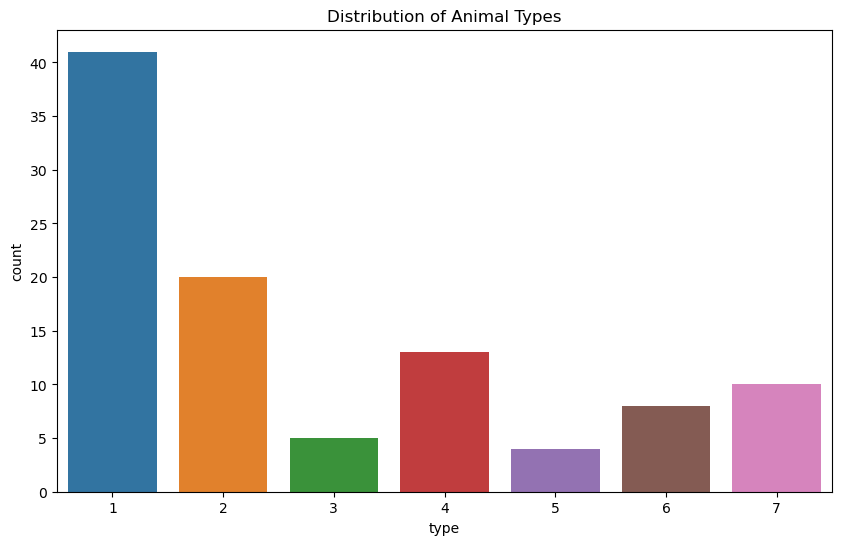

In [291]:
# Visualize the distribution of animal types
plt.figure(figsize=(10, 6))
sns.countplot(x='type', data=data)
plt.title('Distribution of Animal Types')
plt.show()

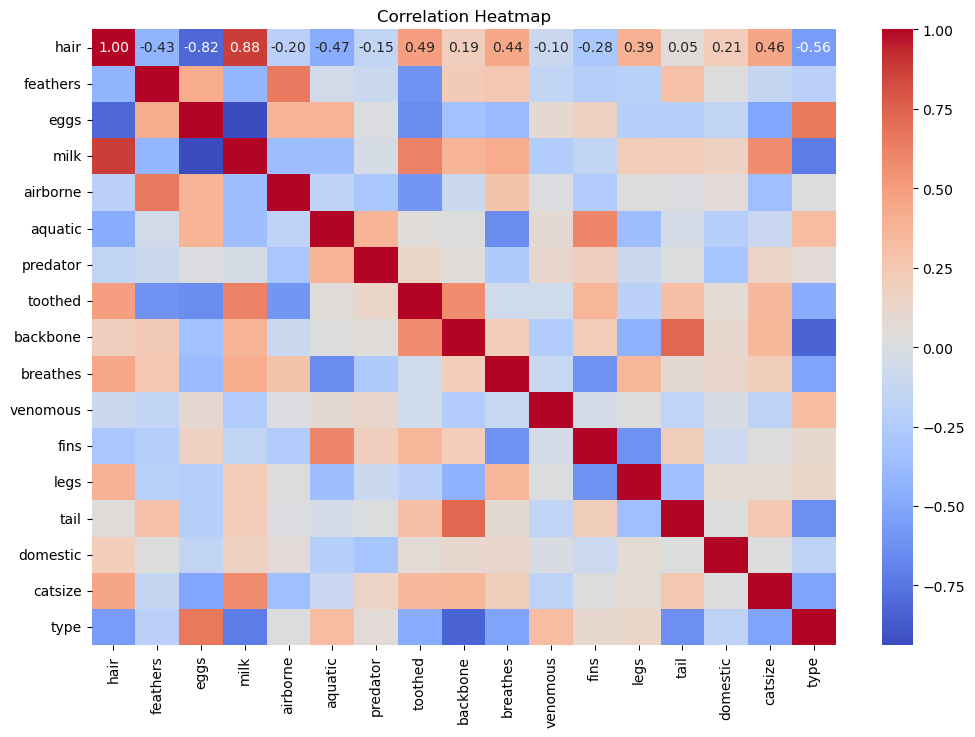

In [292]:
# Visualize correlations
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [293]:
# 2. Data Preprocessing
# Check for missing values
print(data.isnull().sum())

animal name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
type           0
dtype: int64


In [294]:
# Handle categorical data
data['type'] = data['type'].astype('category').cat.codes

In [295]:
# Split features and labels
X = data.drop(['animal name', 'type'], axis=1)
y = data['type']

In [296]:
# Handle outliers (if any)
# Here you might want to use a method such as Z-score or IQR to detect and remove outliers
# For demonstration, we will not implement outlier removal
# 3. Split the dataset into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [297]:
# Check the shapes after splitting
print("X_train shape:", X_train.shape)  # Should be (80, 15)
print("y_train shape:", y_train.shape)  # Should be (80,)

X_train shape: (80, 16)
y_train shape: (80,)


In [298]:
# Scale the features
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)  # Ensure proper column names
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

In [299]:
# Check the shapes after scaling
print("Scaled X_train shape:", X_train_scaled.shape)  # Should match (80, 15)
print("Scaled X_test shape:", X_test_scaled.shape)  # Should match (20, 15)

Scaled X_train shape: (80, 16)
Scaled X_test shape: (21, 16)


In [300]:
# Now you can use .iloc or direct indexing for visualization
X_train_2d = X_train_scaled.iloc[:, :2].values  # First two features for visualization
X_test_2d = X_test_scaled.iloc[:, :2].values

In [301]:
# Standardize the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [302]:
# 4. Implement the K-Nearest Neighbours algorithm
# Choose K and the distance metric
k = 3
knn_2d = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
knn_2d.fit(X_train, y_train)

KNeighborsClassifier(metric='euclidean', n_neighbors=3)

In [303]:
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

In [304]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

In [305]:
print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.95
Precision: 0.92
Recall: 0.95
F1 Score: 0.93
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         2
           2       0.00      0.00      0.00         1
           3       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         1

    accuracy                           0.95        21
   macro avg       0.78      0.83      0.80        21
weighted avg       0.92      0.95      0.93        21



In [306]:
print(y_train.value_counts())
print(y_test.value_counts())

0    29
1    18
3    11
6     9
5     5
4     4
2     4
Name: type, dtype: int64
0    12
5     3
3     2
1     2
6     1
2     1
Name: type, dtype: int64


In [307]:
# 7. Visualize the decision boundaries
# To visualize decision boundaries, we will reduce the dimensions to 2 using PCA or by selecting two features
X_train_2d = X_train[:, :2] 
X_train_2d = X_train[:, [0, 1]]  # Use specific column indices to get the first two features
X_test_2d = X_test[:, [0, 1]]

In [308]:
print("Original X_train shape:", X_train.shape)

Original X_train shape: (80, 16)


In [309]:
print("Number of features in X:", X.shape[1])
print("Columns in original DataFrame:", X.columns)

Number of features in X: 16
Columns in original DataFrame: Index(['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator',
       'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail',
       'domestic', 'catsize'],
      dtype='object')


In [310]:
# Select the first two columns for visualization from NumPy arrays
X_train_2d = X_train[:, :2]  # First two features from the NumPy array
X_test_2d = X_test[:, :2]

In [311]:
# After splitting and scaling
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)  # Keep all columns
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

# If you want to ensure you're only using features, you may have to explicitly define the feature columns:
# Adjust this according to your actual dataset
feature_columns = X.columns  # or a specific subset if needed
X_train = pd.DataFrame(scaler.fit_transform(X_train[feature_columns]), columns=feature_columns)
X_test = pd.DataFrame(scaler.transform(X_test[feature_columns]), columns=feature_columns)

In [312]:
print("Original X_train shape:", X_train.shape)
print("Column names in X:", X.columns)

Original X_train shape: (80, 16)
Column names in X: Index(['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator',
       'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail',
       'domestic', 'catsize'],
      dtype='object')


In [313]:
# 7. Visualize the decision boundaries
X_train_2d = X_train.iloc[:, :2].values  # Get values of the first two features
X_test_2d = X_test.iloc[:, :2].values

In [314]:
knn_2d = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
knn_2d.fit(X_train_2d, y_train)

KNeighborsClassifier(metric='euclidean', n_neighbors=3)

In [315]:
# Create a mesh grid for plotting decision boundaries
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

In [316]:
# Predict class for each point in the mesh
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

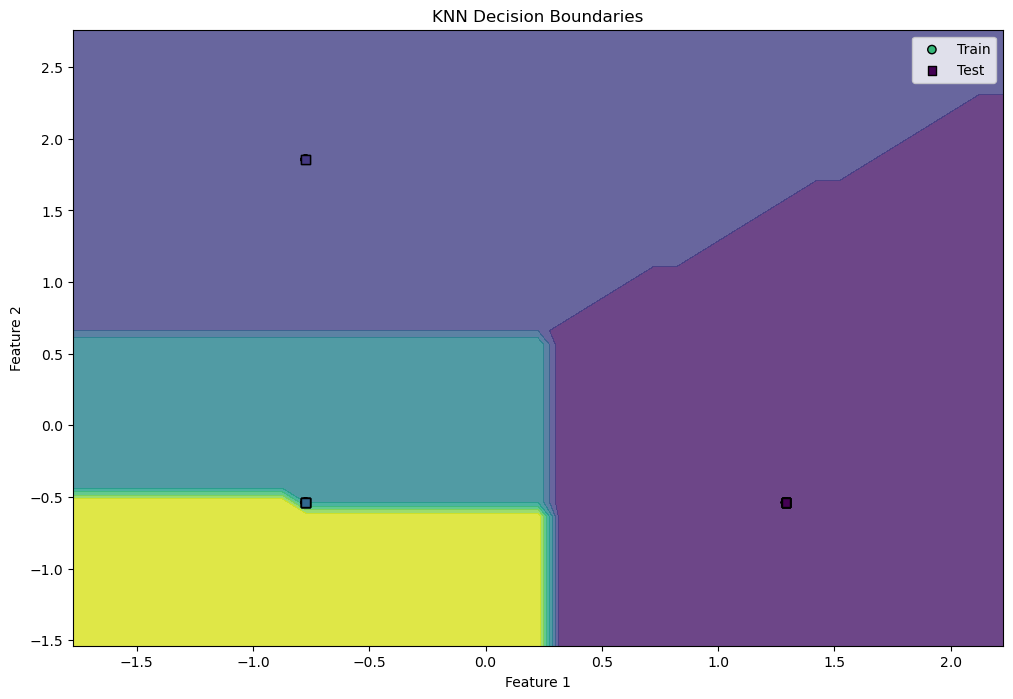

In [317]:
# Plotting
plt.figure(figsize=(12, 8))
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolor='k', marker='o', label='Train')
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=y_test, edgecolor='k', marker='s', label='Test')
plt.title('KNN Decision Boundaries')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

In [318]:
#Interview Questions:
#1. What are the key hyperparameters in KNN?
#n_neighbors: Number of neighbors to consider.
#weights: Weight function used in prediction (uniform, distance).
#algorithm: Algorithm to compute nearest neighbors (auto, ball_tree, kd_tree, brute).
#leaf_size: Leaf size passed to the BallTree or KDTree algorithms.
#metric: Distance metric to use for the tree (euclidean, manhattan, etc.).
#2 What distance metrics can be used in KNN?
#Euclidean distance
#Manhattan distance
#Minkowski distance
#Hamming distance (for categorical data)
#Chebyshev distance